# TUTORIAL: Real-time bias-aware data assimilation
<script src='https://cdnjs.cloudflare.com/ajax/libs/mathjax/2.7.4/MathJax.js?config=default'></script>

* [What is bias-aware data assimilation?](#BADA)
    * [The source of bias: model accuracy vs computational cost](#source)
    * [Algorithmic view on bias-aware data assimilation](#algo)
* [What is bias-aware data assimilation, a bit more technically?](#tech)
    * [Aleatoric and epistemic uncertainties](#UQ)
    * [Augmented state-space formulation](#augment)
    * [Model bias in a stochastic ensemble framework](#bias-stoch)
    * [How do we estimate the bias in time?](#evolution)
* [The regularized ensemble Kalman filter](#rEnKF)
    * [Test case: van der Pol model with manually added bias](#test)
* [Conclusions](#conclusions)


<a class="anchor" id="BADA"></a>
# 1. What is bias-aware data assimilation? 
Real-time data assimilation combines quick estimates of a physical state from a numerical model with experimental data.  In reality, numerical models are not a perfect representation of the physical quantity that we aim to predict because they typically rely on assumptions and simplifications to reduce the computational cost, i.e., they have an inherent model bias.

<br /> 

<a class="anchor" id="source"></a>
## 1.1. The source of bias: model accuracy vs computational cost 

The choice of physical model plays a key role in the assimilation. Numerical models are mathematical representations of the processes that govern the behaviour of a physical system. For example, in weather forecasting, models simulate how the atmosphere evolves over time based on physical equations describing fluid dynamics, thermodynamics, etc. The more physical information we add to the model, the higher the accuracy of the model estimates. However, the computational requirements increase with the model complexity.

To perform real-time data assimilation we need quick estimates of the physical system. Thus, performing real-time high-fidelity modelling is not plausible in realistic scenarios. In order to apply real-time data assimilation to low-fidelity models, we must provide an estimate of the bias in the numerical model, i.e., the model error that we introduce when simplifying the physical equations.  

<a><img src="../../docs/figs/DA/models_pyramid.png" width=600px></a>



<a class="anchor" id="algo"></a>
## 1.2. Algorithmic view on bias-aware data assimilation 

Algorithmically, we can summarize the bias-aware data assimilation process as:
1. <em>Forecast</em>: propagate the imperfect numerical model in time to provide a <strong><font color="#e0915c">biased forecast</font></strong> when <strong><font color="#24678d">observation</font></strong> data become available.
2. <em>Bias correction</em>: provide an estimate of the bias, and project the <strong><font color="#e0915c">biased forecast</font></strong> into an <strong><font color="#a561d0">unbiased forecast</font></strong><font color="#2a2a2a"></font>. 
3. <em>Assimilation</em>: combine optimally the <strong><font color="#a561d0">unbiased forecast</font></strong> with the <strong><font color="#24678d">observations</font></strong>. The direct assimilation results in an <strong><font color="#91e05c">unbiased analysis</font></strong>, and the <strong><font color="#76cae9">biased analysis</font></strong> is an indirect by-product of the assimilation.
4. <em>Update</em>: the <strong><font color="#76cae9">biased analysis</font></strong> is the initial condition for the new forecast step.

<a><img src="../../docs/figs/DA/wBADA.gif" width=800px></a> 

<br /> 

<a class="anchor" id="tech"></a>
# 2. What is bias-aware data assimilation, a bit more technically? 

In this section, we revisit the formulation of the stochastic framework introduced in tutorial ***11_ensemble-DA_intro.ipynb*** and we extend it to account for model biases. 

<br />
<a class="anchor" id="UQ"></a>

## 2.1. Aleatoric and epistemic uncertainties  
 

First, we discuss the statistical hypotheses on the aleatoric uncertainties. The aleatoric uncertainties contaminate the state and parameters as 

$$
     \boldsymbol{\phi}  +  \boldsymbol{\epsilon}_\phi =  \boldsymbol{\phi}^\dagger, \quad
     \boldsymbol{\alpha} +  \boldsymbol{\epsilon}_\alpha =  \boldsymbol{\alpha}^\dagger,
$$

where $\dagger$ indicates the true quantity (which is unknown). The aleatoric uncertainties are modelled as Gaussian distributions   

$$
     \boldsymbol{\epsilon}_\phi \sim \mathcal{N}( \boldsymbol{0},  \boldsymbol{\mathsf{C}}_{\phi\phi} ), \quad  \boldsymbol{\epsilon}_\alpha \sim \mathcal{N}( \boldsymbol{0},  \boldsymbol{\mathsf{C}}_{\alpha\alpha} ),
$$

where $\mathcal{N}( \boldsymbol{0},  \boldsymbol{\mathsf{C}})$ is a normal distribution with zero mean and covariance $\boldsymbol{\mathsf{C}}$. Second, we discuss model biases, which are epistemic uncertainties. The model bias is defined as the expected difference between the true observable and the model observable, i.e., 

$$
   \boldsymbol{b}   =  \boldsymbol{d}^{\dagger} -\mathbb{E}( \boldsymbol{q}). 
$$

Hence, the bias-corrected model observable is

$$
     \boldsymbol{y} =  \boldsymbol{q} +  \boldsymbol{b} +  \boldsymbol{\epsilon}_q, 
$$

where $\boldsymbol{\epsilon}_q \sim \mathcal{N}( \boldsymbol{0},  \boldsymbol{\mathsf{C}}_{qq})$. (If the model is unbiased, $\boldsymbol{d}^{\dagger} =\mathbb{E}( \boldsymbol{q})$.) 


The final model equations, which define the first source of information on the system, are

$$
\begin{aligned} 
\left\{
\begin{array}{rcl}
      \mathrm{d} \boldsymbol{\phi}&=& \mathcal{F}\left( \boldsymbol{\phi+ \boldsymbol{\epsilon}_\phi, \alpha+ \boldsymbol{\epsilon}_\alpha} \right)  \mathrm{d} t \\
       \boldsymbol{y} &=& \mathcal{M}( \boldsymbol{\theta},  \boldsymbol{\phi}) +  \boldsymbol{b}+  \boldsymbol{\epsilon}_q
\end{array}
\right.
\end{aligned}
$$

This set of equations is not closed because we need a model for the model bias. To infer it, we analyse  the residuals between the forecast and the observations, which are also known as <em>innovations</em>

$$
    \boldsymbol{i} =  \boldsymbol{d} -  \boldsymbol{q}. 
$$

As discussed in tutorial ***11_ensemble-DA_intro.ipynb***, the experimental data are affected by aleatoric noise such that $\boldsymbol{d} + \boldsymbol{\epsilon}_d =  \boldsymbol{d}^{\dagger}$, where  $\boldsymbol{\epsilon}_d \sim \mathcal{N}(\boldsymbol{0}, \boldsymbol{\mathsf{C}}_{dd})$ and  $\boldsymbol{\mathsf{C}}_{dd}$ is a diagonal matrix of the noise variances. With this, the expected value of the innovation is 

$$
    \mathbb{E}( \boldsymbol{i}) =  \boldsymbol{b}, 
$$

i.e., the expected innovation is the model bias. 


<br />




## 2.2. Augmented state-space formulation <a class="anchor" id="augment"></a>
The augmented form of the state-space formulation of the model, accounting for the model bias, yields 

$$
\begin{aligned}
\left\{
\begin{array}{rcl}
      \mathrm{d}\begin{bmatrix}
      \boldsymbol{\phi}\\
      \boldsymbol{\alpha}\\
      \boldsymbol{q}
 \end{bmatrix} &=& 
 \begin{bmatrix}
     \mathcal{F}( \boldsymbol{\phi}+ \boldsymbol{\epsilon}_\phi, \boldsymbol{\alpha}+ \boldsymbol{\epsilon}_\alpha)\\
      \boldsymbol{0}_{N_\alpha}\\
      \boldsymbol{0}_{N_q}
 \end{bmatrix} 
{ \mathrm{d} t}  \\
 \boldsymbol{y} &=&  \boldsymbol{q} +  \boldsymbol{b}  +  \boldsymbol{\epsilon}_{q}
\end{array}
\right.
\quad\leftrightarrow  \quad
\left\{
\begin{array}{rcl}
 \mathrm{d} \boldsymbol{\psi} &=&  \boldsymbol{\mathsf{F}}\left( \boldsymbol{\psi} + \boldsymbol{\epsilon}_\psi\right){ \mathrm{d} t}  \\
 \boldsymbol{y} &=&  \boldsymbol{\mathsf{M}} \boldsymbol{\psi} +  \boldsymbol{b}  +  \boldsymbol{\epsilon}_{q}
\end{array}
\right.
\end{aligned}
$$

where $\boldsymbol{\mathsf{F}}( \boldsymbol{\psi})$ and $\boldsymbol{\epsilon}_\psi$ are the augmented nonlinear operator and aleatoric uncertainties, respectively; $\boldsymbol{\mathsf{M}} = \left[ \boldsymbol{0}~\big|~\mathbb{I}_{N_q}\right]$ is the linear measurement operator; and $\boldsymbol{0}_{N_\alpha}$ and $\boldsymbol{0}_{N_q}$ are vectors of zeros (because the parameters are constant in time, and $\boldsymbol{q}$ is not integrated in time but it is only computed at the analysis step).  

<br />

## 2.3. Model bias in a stochastic ensemble framework <a class="anchor" id="bias-stoch"></a>
The underlying assumption of ensemble methods is that the ensemble is Gaussian distributed, i.e,  $\boldsymbol{\psi}_j\sim\mathcal{N}(\bar{ \boldsymbol{\psi}},  \boldsymbol{\mathsf{C}}_{\psi\psi})$. Within an ensemble framework, we approximate the model bias  with the ensemble statistics  

$$
\begin{aligned}
     \boldsymbol{b} &\approx \boldsymbol{d}^{\dagger} -  \boldsymbol{\mathsf{M}}\bar{ \boldsymbol{\psi}}, 
\end{aligned}
$$

Hence, the innovation of the ensemble mean can be approximated as 

$$
    \bar{ \boldsymbol{i}} =  \boldsymbol{d} -  \boldsymbol{\mathsf{M}}\bar{ \boldsymbol{\psi}} \approx  \boldsymbol{b}.  
$$


___

#### Exercise 

<em><font color="#7CB9E8">&emsp; How does the definition of the innovation change if we did not assume unbiased observations? That is, $\mathbb{E}(\boldsymbol{d}) \neq  \boldsymbol{d}^{\dagger}$.</font></em>

___

<a class="anchor" id="evolution"></a>
## 2.4. How do we estimate the bias in time? 

The model bias is defined as the expected difference between the true observable and the model observable. Therefore, it is unknown a priori (colloquially, it is an <em>unknown unknown</em>).  The model bias may be a function of the physical state, the environment or even a function of time. 


Recent advances in machine learning for data-driven modelling allow us to develop surrogate models of dynamical systems using neural networks. That is, we can use a neural network to estimate the bias of the low-order numerical models. Specifically, we employ an echo state network (ESN) to infer the model bias.  ESNs are suitable for real-time data assimilation because 
1. they are recurrent neural networks, i.e., they are designed to learn temporal dynamics in data; 
2. they are based on reservoir computing, hence they are universal approximators;
3. they are general nonlinear autoregressive models; and 
4. training an ESN consists of solving a linear regression problem, which provides a global minimum without backpropagation.

The architecture of the model bias estimation by ESN is illustrated below. The network runs in open loop only during training (left), whilst during operation the ESN performs one open-loop step when observations are available and then runs autonomously in closed loop until the next analysis (right). 


<a><img src="../../docs/figs/DA/ESN-basic-config.png" width=800px></a> 







<a class="anchor" id="rEnKF"></a>
# 3. The bias-regularized ensemble Kalman filter 

The objective function in a bias-regularized data assimilation framework contains three norms

$$
\begin{aligned}
\mathcal{J}( \boldsymbol{\psi}_j) = &\left\| \boldsymbol{\psi}_j- \boldsymbol{\psi}_j^\mathrm{f}\right\|^2_{ \boldsymbol{\mathsf{C}}^{\mathrm{f}^{-1}}_{\psi\psi}} +
 \left\|{ \boldsymbol{y}}_j- \boldsymbol{d}_j\right\|^2_{\boldsymbol{\mathsf{C}}^{-1}_{dd}}+\gamma\left\| \boldsymbol{b}_j\right\|^2_{ \boldsymbol{\mathsf{C}}^{-1}_{bb}}, \quad \mathrm{for} \quad j=0,\dots,m-1
\end{aligned}
$$

where the superscript 'f' indicates 'forecast'; the operator $\left\|\cdot\right\|^2_{ \boldsymbol{\mathsf{C}}^{-1}}$ is the $L_2$-norm weighted by the semi-positive definite matrix ${ \boldsymbol{\mathsf{C}}^{-1}}$; $\gamma\geq0$ is a user-defined bias regularization factor; and $\boldsymbol{b}_j$ is the model bias of each ensemble member. For simplicity, we define the bias in the ensemble mean, such that  $\boldsymbol{b}_j =  \boldsymbol{b}$ for all $j$. From left to right, the norms on the right-hand-side of the cost function measure 
1. the spread of the ensemble prediction, 
2. the distance between the bias-corrected estimate and the observables, and 
3. the model bias norm.

The analytical solution of the bias-regularized ensemble Kalman filter (r-EnKF), which globally minimizes the cost function with respect to $\boldsymbol{\psi}_j$, is 

$$
\begin{aligned}
     \boldsymbol{\psi}_j^\mathrm{a} &= 
     \boldsymbol{\psi}_j^\mathrm{f} + 
     \boldsymbol{\mathsf{K}}_\mathrm{r} \left[\left(\mathbb{I}+  \boldsymbol{\mathsf{J}}\right)^\mathrm{T}\left( \boldsymbol{d}_j -  \boldsymbol{y}_j^\mathrm{f}\right) - \gamma  \boldsymbol{\mathsf{C}}_{dd} \boldsymbol{\mathsf{C}}^{-1}_{bb} \boldsymbol{\mathsf{J}}^\mathrm{T} \boldsymbol{b}^\mathrm{f}\right], \quad j=0,\dots,m-1
\end{aligned}
$$

with

$$
\begin{aligned}
 \boldsymbol{\mathsf{K}}_\mathrm{r} =  \boldsymbol{\mathsf{C}}_{\psi\psi}^\mathrm{f} \boldsymbol{\mathsf{M}}^\mathrm{T}\left[ \boldsymbol{\mathsf{C}}_{dd} + (\mathbb{I}+  \boldsymbol{\mathsf{J}})^\mathrm{T}(\mathbb{I}+  \boldsymbol{\mathsf{J}}) \boldsymbol{\mathsf{M}} \boldsymbol{\mathsf{C}}_{\psi\psi}^\mathrm{f} \boldsymbol{\mathsf{M}}^\mathrm{T} + \gamma  \boldsymbol{\mathsf{C}}_{dd} \boldsymbol{\mathsf{C}}^{-1}_{bb} { \boldsymbol{\mathsf{J}}}^\mathrm{T}\boldsymbol{\mathsf{J}} \boldsymbol{\mathsf{M}} \boldsymbol{\mathsf{C}}_{\psi\psi}^\mathrm{f} \boldsymbol{\mathsf{M}}^\mathrm{T}\right]^{-1},
\end{aligned}
$$

where 'a'  stands for 'analysis', i.e, the optimal state of the assimilation; $\boldsymbol{\mathsf{K}}_\mathrm{r}$ is the regularized Kalman gain matrix; and $\boldsymbol{\mathsf{J}} =  \mathrm{d}  \boldsymbol{b}/ \mathrm{d} \boldsymbol{\mathsf{M}} \boldsymbol{\psi}$ is the Jacobian of the bias estimator. We prescribe  $\boldsymbol{\mathsf{C}}_{dd} =  \boldsymbol{\mathsf{C}}_{bb}$ because the model  bias is defined in the observable space.  We use $\gamma$ to tune the norm of the bias. The optimal state and parameters are

$$
\begin{aligned}
   \begin{bmatrix}
        \boldsymbol{\phi}_j^\mathrm{a}\\
        \boldsymbol{\alpha}_j^\mathrm{a}
   \end{bmatrix}
   = 
   \begin{bmatrix}
        \boldsymbol{\phi}_j^\mathrm{f}\\
        \boldsymbol{\alpha}_j^\mathrm{f}
   \end{bmatrix} + 
   \overbrace{
   \begin{bmatrix}
        \boldsymbol{\mathsf{C}}_{\phi q}^\mathrm{f}\\
        \boldsymbol{\mathsf{C}}_{\alpha q}^\mathrm{f}
   \end{bmatrix}
       \left\{ \boldsymbol{\mathsf{C}}_{dd}+(\mathbb{I}+  \boldsymbol{\mathsf{J}})^\mathrm{T} (\mathbb{I}+  \boldsymbol{\mathsf{J}}) \boldsymbol{\mathsf{C}}_{qq}^\mathrm{f}+\gamma  { \boldsymbol{\mathsf{J}}}^\mathrm{T}\boldsymbol{\mathsf{J}} \boldsymbol{\mathsf{C}}_{qq}^\mathrm{f}\right\}^{-1}
   }^\mathrm{Regularized\, Kalman \, gain,\,  \boldsymbol{\mathsf{K}}_\mathrm{r}} \Big[\left(\mathbb{I}+\boldsymbol{\mathsf{J}}\right)^\mathrm{T}\left(\boldsymbol{d}_j -  \boldsymbol{y}_j^\mathrm{f}\right)- \gamma  \boldsymbol{\mathsf{J}}^\mathrm{T} \boldsymbol{b}^\mathrm{f}\Big]
\end{aligned}
$$

The r-EnKF defines a 'good' analysis from a biased model if  the unbiased state $\boldsymbol{y}$ matches the truth, and the model bias $\boldsymbol{b}$ is small relative to the truth. The underlying assumptions of this work are that (i) our low-order model is qualitatively accurate such that the model bias $\boldsymbol{b}^\mathrm{f}$ has a small norm; and (ii) the sensors are properly calibrated.

<br />

___

    
#### Exercise

<em><font color="#7CB9E8"> Prove that in the limiting case when the assimilation framework is unbiased, the r-EnKF becomes the bias-unregularized EnKF, which we discussed in the previous tutorials.</font></em>

___


The analysis in code, for an ensemble `Af` (N x m) with the observables in its last rows, the data `d`, the bias estimate `b` (Nq x 1) and its Jacobian `J` (the implementation is `romda.estimators.rEnKF`):

```python
def rEnKF_analysis(Af, d, Cdd, M, b, J, gamma, rng):
    m, Iq = Af.shape[1], np.eye(len(d))
    Psi = Af - Af.mean(axis=1, keepdims=True)              # anomalies of the ensemble
    S = M @ Psi                                            # anomalies of the observables
    D = rng.multivariate_normal(d, Cdd, m).T               # perturbed observations
    Y = M @ Af + b                                         # bias-corrected forecast
    Cqq = S @ S.T
    C = (m - 1) * Cdd + (Iq + J).T @ (Iq + J) @ Cqq + gamma * J.T @ J @ Cqq
    K = Psi @ S.T @ np.linalg.inv(C)                       # regularized Kalman gain
    return Af + K @ ((Iq + J).T @ (D - Y) - gamma * J.T @ b)
```

<a id="test"></a>
## 3.1. Test case: van der Pol model with manually added bias

We repeat the first test case of [Nóvoa, Racca & Magri (2023)](https://doi.org/10.1016/j.cma.2023.116502) with the settings of its Table 3 (`scripts/thermoacoustics/cmame2023` replicates the figures of the paper). The experiment is a twin experiment: the truth is a van der Pol oscillator with the bias $b = \cos\eta$ added to its observable, $\eta$, and the forecast model is the van der Pol oscillator without the bias. The plotting helpers are in `aux_1X.py`.

### i. The truth and the observations

334 observations, one every 0.075 t_CR
relative error of the truth without its bias: 0.165


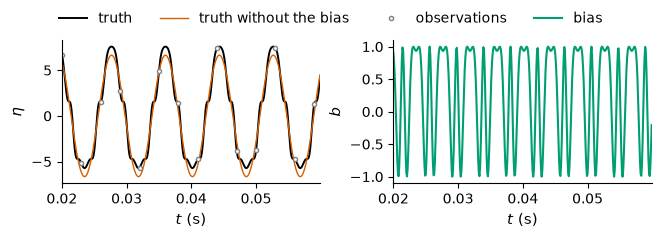

In [1]:
import warnings

import numpy as np
from aux_1X import (final_parameters, plot_estimates_16, plot_parameters_16, plot_regularization_16, plot_training_16,
                    plot_truth_16)
from romda.metrics import relative_error, window_errors
from romda.models.physical import VdP
from romda.observations import Observations, variance_fraction_covariance
from romda.utils import seed_noise

warnings.filterwarnings('ignore', category=UserWarning)
seed_noise(0)                                    # the noise of the observations and of the filters

true_parameters = dict(beta=75., zeta=55., kappa=3.4)
truth = Observations(model=VdP, **true_parameters, law='tan', dt=1e-4,
                     t_min=1.98, t_start=2., t_stop=3., t_max=4.5,   # the clock starts at t_min: data from 0.02 s to 1.02 s
                     Nt_obs=30,                                      # time steps between observations
                     manual_bias='cosine',                           # b = cos(eta)
                     add_noise=True, noise_type='gauss, mult', noise_level=0.01)

t_CR = VdP.t_CR                                  # characteristic time of the oscillator
after = (truth.t_true >= truth.t_obs[-1]) & (truth.t_true < truth.t_obs[-1] + t_CR)   # first t_CR after the assimilation
true_bias_error = relative_error(truth.y_true[after], (truth.y_true - truth.b_true)[after])
print(f'{len(truth.t_obs)} observations, one every {truth.dt_obs / t_CR:.3f} t_CR')
print(f'relative error of the truth without its bias: {true_bias_error:.3f}')
plot_truth_16(truth, t_CR)

The bias distorts the waveform and leaves the frequency unchanged. The truth without its bias, i.e., the forecast model with the true parameters, has a relative error of 0.165: this is the reference for the model estimates below.

### ii. The ensemble

The forecast model has three uncertain parameters, which the filter estimates with the state. The members start from the state of the model with the prior mean of the parameters, $(\beta, \zeta, \kappa) = (70, 60, 4)$, and their parameters are drawn from a normal distribution with a standard deviation of 25 % of the mean.

In [2]:
from romda.estimators import EnKF, rEnKF
from romda.run import draw_state_after_spinup, reflect_into_limits

prior = dict(beta=[35., 105.], zeta=[30., 90.], kappa=[2., 6.])     # mean -/+ two standard deviations


def create_filter(estimator, **options):
    """A filter with m = 10 members on the limit cycle of the prior model at the start of the experiment."""
    filt = estimator(parent_model=VdP, dt=truth.dt, law='tan', m=10, std_phi=0.25, std_alpha=prior,
                     distribution_alpha='normal', inflation=1.002, **options)
    draw_state_after_spinup(filt.model, VdP(dt=truth.dt, law='tan'), spinup_cr=49.5, std_phi=0.25)
    reflect_into_limits(filt.model)              # parameters outside the limits of the model are reflected inside
    return filt


Cdd = variance_fraction_covariance(truth, 0.01)  # observation error variance: 1 % of max|d|^2

### iii. An echo state network to estimate the bias

The network is trained before the assimilation, on the differences between the truth and $L = 10$ realizations of the forecast model with parameters drawn within 50 % of the prior mean. It maps the innovation to the bias, and holds one bias state, that of the ensemble mean.

RMS of the training biases: 3.64; RMS of the true bias: 0.78


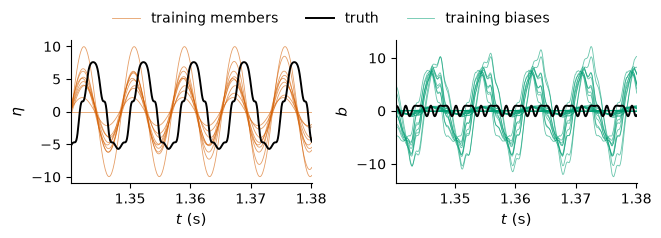

In [3]:
from romda.bias_estimators import ESN_bias
from romda.utils import set_working_directories

training_data_filename = set_working_directories('vdp')[1] + 'Tutorial_16_cosine_bias'

bias_estimator = ESN_bias(rom=create_filter(rEnKF).model, reference_data=truth,
                          training_data_filename=training_data_filename,
                          # training data
                          L=10, augment_data=True, std_phi=0.5, std_alpha=prior, noise=0.03,
                          correlation_based_training=False, biased_observations=False,
                          t_train=1.0, t_val=0.1, t_test=0.04,
                          # network and hyperparameter search
                          N_ens=1, N_units=100, N_wash=30, upsample=5,
                          scale_bias_in=True, regularize_bias_out=True,    # conventions of the paper
                          rho_range=[0.7, 1.05], sigma_in_range=[-5., 0.], tikh_range=[1e-16],
                          N_folds=4, N_grid=4, N_func_evals=20, plot_training=False,
                          force_retrain=True)   # train here; a stored network would skip the training data

training_data = np.load(training_data_filename, allow_pickle=True)
rms = lambda b: np.sqrt(np.mean(b ** 2))
print(f"RMS of the training biases: {rms(training_data['data'][..., 0]):.2f}; RMS of the true bias: {rms(truth.b_true):.2f}")
plot_training_16(truth, training_data, t_CR)

The network is not trained on the true bias, which is unknown. The training biases are larger than the true bias (RMS of 3.64 against 0.78) because the training members differ from the truth in amplitude and phase. The network therefore represents a family of plausible biases, and the assimilation selects one of them.

### iv. Data assimilation with and without a bias estimator

We compare three filters on the same observations: the EnKF with no bias estimator, the r-EnKF without regularization ($\gamma = 0$) and the r-EnKF with $\gamma = 10$. After the last observation, each filter forecasts for two characteristic times, $t_\mathrm{CR}$, without data. The errors are relative root-mean-square errors with respect to the truth over the first $t_\mathrm{CR}$ after the assimilation.

In [4]:
from romda.data_assimilation import run_da_loop


def assimilate(gamma=None):
    """The EnKF with no bias estimator (`gamma` = None), or the r-EnKF with the regularization factor `gamma`."""
    if gamma is None:
        filt = create_filter(EnKF)
    else:
        filt = create_filter(rEnKF, bias_regularization=gamma)
        filt.bias = bias_estimator.copy()
    # washout: the network is synchronized with the innovations before the first analysis
    filt = run_da_loop(filt, truth, Cdd=Cdd, t_extra=2 * t_CR, washout=gamma is not None)
    filt.close()                                 # the pool of workers of the ensemble
    return filt


def errors(filt):
    t_end = truth.t_obs[-1]
    return window_errors(filt, truth, t_end, t_end + t_CR)


runs = {'EnKF, no bias estimator': assimilate(), r'r-EnKF, $\gamma = 0$': assimilate(0.),
        r'r-EnKF, $\gamma = 10$': assimilate(10.)}

print(f"{'':26s}{'model':>8s}{'bias-corrected':>16s}{'beta':>8s}{'zeta':>8s}{'kappa':>8s}{'(beta - zeta) / kappa':>24s}")
for name, filt in runs.items():
    e, a = errors(filt), final_parameters(filt, truth.t_obs[-1])
    print(f"{name.replace('$', '').replace(chr(92) + 'gamma', 'gamma'):26s}{e['model']:8.3f}{e['corrected']:16.3f}"
          f"{a['beta']:8.1f}{a['zeta']:8.1f}{a['kappa']:8.2f}{(a['beta'] - a['zeta']) / a['kappa']:24.2f}")
a = true_parameters
print(f"{'truth without its bias':26s}{true_bias_error:8.3f}{'':16s}{a['beta']:8.1f}{a['zeta']:8.1f}{a['kappa']:8.2f}"
      f"{(a['beta'] - a['zeta']) / a['kappa']:24.2f}")

                             model  bias-corrected    beta    zeta   kappa   (beta - zeta) / kappa
EnKF, no bias estimator      0.167           0.167    76.3    55.7    3.49                    5.92
r-EnKF, gamma = 0            0.564           0.063    74.0    66.4    4.26                    1.78
r-EnKF, gamma = 10           0.166           0.074    87.2    64.9    3.60                    6.22
truth without its bias       0.165                    75.0    55.0    3.40                    5.88


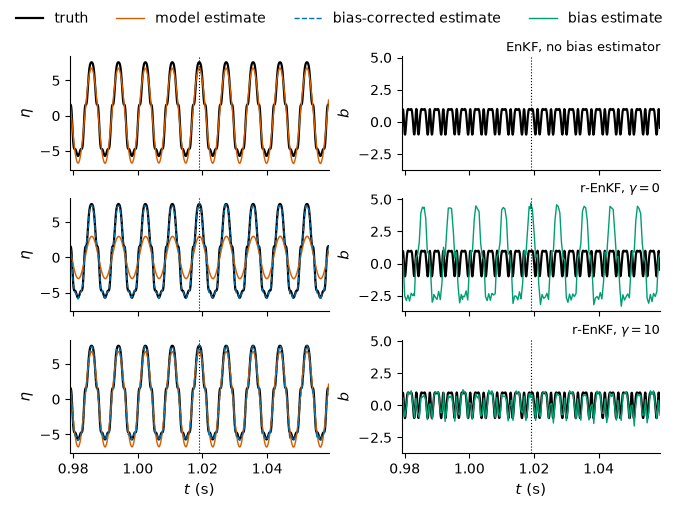

In [5]:
plot_estimates_16(runs, truth, t_CR)

- **EnKF with no bias estimator.** The error of the model estimate, 0.167, is that of the truth without its bias (0.165): the filter calibrates the model and leaves the bias in the estimate.
- **r-EnKF with $\gamma = 0$.** The bias-corrected estimate is accurate (0.063), but the error of the model estimate is 0.564, i.e., 3.4 times that of the truth without its bias. The sum of the model and the bias is constrained by the data, whereas the split between them is not: the network absorbs part of the oscillation.
- **r-EnKF with $\gamma = 10$.** The penalty on the norm of the bias makes the split unique. The model estimate is as accurate as that of the EnKF (0.166), and the bias-corrected estimate has less than half of its error (0.074 against 0.167).

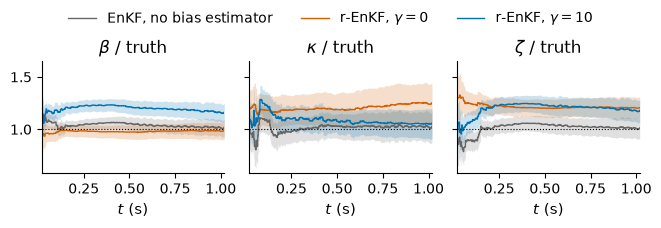

In [6]:
plot_parameters_16(runs, true_parameters, truth.t_obs)

The parameters are not identified one by one: with $\gamma = 10$, $\beta$ and $\zeta$ end 16 % and 18 % above their true values (87.2 and 64.9 against 75 and 55), whereas $(\beta - \zeta)/\kappa$ ends within 6 % of the truth (6.22 against 5.88). Without regularization, this combination ends at 1.78, which is consistent with the small amplitude of the model estimate. The EnKF with no bias estimator infers parameters that are as close to the truth, $(\beta - \zeta)/\kappa = 5.92$: in this case, the benefit of the r-EnKF is the estimate of the bias, not a more accurate model.

### v. The regularization factor

gamma                 0     0.5       1       2       5      10      20
model             0.564   0.466   0.388   0.273   0.167   0.166   0.166
bias-corrected    0.063   0.065   0.068   0.071   0.074   0.074   0.074


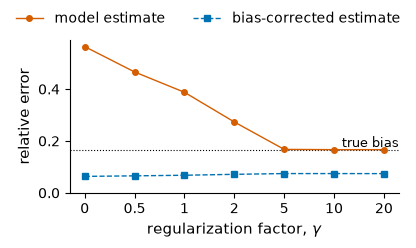

In [7]:
gammas = (0., 0.5, 1., 2., 5., 10., 20.)
sweep = [errors(assimilate(gamma)) for gamma in gammas]

print('gamma          ' + ''.join(f'{g:8g}' for g in gammas))
print('model          ' + ''.join(f"{e['model']:8.3f}" for e in sweep))
print('bias-corrected ' + ''.join(f"{e['corrected']:8.3f}" for e in sweep))
plot_regularization_16(gammas, [e['model'] for e in sweep], [e['corrected'] for e in sweep], true_bias_error)

The error of the model estimate decreases from 0.564 at $\gamma = 0$ to 0.167 at $\gamma = 5$, and remains at 0.166 for $\gamma = 10$ and $20$, whilst the error of the bias-corrected estimate increases from 0.063 to 0.074 only. Any $\gamma \geq 5$ is therefore a suitable choice in this case. The limit $\gamma = 0$ is the bias-aware filter without regularization, and a filter with no bias estimator ($\boldsymbol{b} = \boldsymbol{0}$, $\boldsymbol{\mathsf{J}} = \boldsymbol{0}$) is the EnKF of the previous tutorials.

___

#### Exercise

<em><font color="#7CB9E8">&emsp; Repeat the experiment with another bias (`manual_bias='periodic'` or `'linear'`) and with a single training member ($L = 1$). Which conclusions hold? </font></em>

___

<a class="anchor" id="conclusions"></a>
# 4. Conclusions

A low-order model has a bias, which a filter that assumes an unbiased model leaves in its estimate. The r-EnKF estimates the state, the parameters and the bias together, with an echo state network as the model of the bias. In the van der Pol test case with the bias $b = \cos\eta$, we find that

1. the EnKF with no bias estimator calibrates the model, but its error (0.167) cannot fall below that of the truth without its bias (0.165);
2. a bias estimator without regularization ($\gamma = 0$) provides an accurate bias-corrected estimate (0.063) with an inaccurate model (0.564), because the split between the model and the bias is not unique; and
3. the regularization ($\gamma \geq 5$) selects the bias of small norm: the model is as accurate as that of the EnKF and the error of the bias-corrected estimate is less than half of it (0.074).

These results are one realization of the filter and of the noise. The combinations of parameters that the data constrain are inferred, not each parameter. Tutorial ***21_TABADA_Rijke_CMAME.ipynb*** applies the r-EnKF to the Rijke tube, and `scripts/thermoacoustics/cmame2023` repeats the study of the paper over the number of training members and $\gamma$.